In [ ]:
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


Weights and Biases

In [ ]:
!pip install wandb -qU

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.0/23.0 MB 117.1 MB/s eta 0:00:00


In [ ]:
import wandb
wandb.login()

True

In [ ]:
import sys
import os
from google.colab import drive

drive.mount('/content/drive')
sys.path.append("/content/drive/MyDrive/Crop Disease Detection Super Resolution")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from split_data import split_data

# Corrected path based on your link:
initial_train_dir = "/content/drive/MyDrive/Crop Disease Detection Super Resolution/plantvillage_data/PlantVillage-Dataset-master/PlantVillage-Dataset-master/raw/color"
new_train_dir = "/content/drive/MyDrive/Crop Disease Detection Super Resolution/platvillage_data/color_images"

if not os.path.exists(new_train_dir):
    print("Splitting data... this may take a moment.")
    split_data(initial_train_dir, new_train_dir, train_ratio=0.6, val_ratio=0.2, test_ratio=0.2)
else:
    print("Data already split.")

Data already split.


In [ ]:
# from training_utils import (load_class_names, load_plant_balanced_image_file_sample,
#                             data_summary, summarize_image_attributes, build_plant_dict)
# import matplotlib.pyplot as plt
# from PIL import Image

# train_dir = "/content/drive/MyDrive/Crop Disease Detection Super Resolution/platvillage_data/color_images/train"

# # 1. Load Data
# class_names = load_class_names(train_dir)
# plant_dict = build_plant_dict(class_names)
# sample_image_files, sample_labels, sample_classes = load_plant_balanced_image_file_sample(train_dir, plant_dict, 500)

# # 2. Manual Flattening to ensure no lists remain
# flat_images = []
# for item in sample_image_files:
#     if isinstance(item, list): flat_images.extend(item)
#     else: flat_images.append(item)

# # 3. Summaries
# data_summary(train_dir, sample_labels, class_names)
# summarize_image_attributes(flat_images)

# # 4. CUSTOM PLOTTING (Replaces the broken graph_class_examples function)
# def manual_graph_examples(image_paths, classes, num_examples=5):
#     plt.figure(figsize=(15, 5))
#     for i in range(min(num_examples, len(image_paths))):
#         plt.subplot(1, num_examples, i+1)
#         # Ensure path is a string
#         img_path = str(image_paths[i])
#         img = Image.open(img_path)
#         plt.imshow(img)
#         plt.title(str(classes[i]).split('___')[-1])
#         plt.axis('off')
#     plt.show()

# manual_graph_examples(flat_images, sample_classes)

In [ ]:
# import wandb
# import torch

# # 1. DEFINE PATHS
# project_path = "/content/drive/MyDrive/Crop Disease Detection Super Resolution"

# def execute_file(filename):
#     path = os.path.join(project_path, filename)
#     with open(path, 'r') as f:
#         exec(f.read(), globals())
#     print(f" Executed {filename}")

# # 2. RUN YOUR FILES INTO MEMORY
# try:
#     import os
#     execute_file("generators.py")
#     execute_file("discriminators.py")
#     execute_file("dataset_utils.py")
#     execute_file("training_loop.py")
# except Exception as e:
#     print(f" Execution failed: {e}")

# # 3. Hyperparameters
# lr, batch_size, num_epochs = 0.0002, 16, 10
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 4. W&B Initialization
# wandb.init(
#     project="Agricultural-Super-Resolution",
#     name="gan-training-v1",
#     config={"lr": lr, "batch_size": batch_size, "epochs": num_epochs},
#     reinit=True
# )

In [ ]:
# import torch
# import os
# import inspect

# # 1. Setup Device
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 2. Initialize Models
# generator = AgriculturalGenerator().to(device)
# discriminator = AgriculturalDiscriminator().to(device)
# print("✅ Models (Generator & Discriminator) moved to GPU.")

# # 3. Exhaustive Function Search
# train_dir = "/content/drive/MyDrive/Crop Disease Detection Super Resolution/platvillage_data/color_images/train"
# project_path = "/content/drive/MyDrive/Crop Disease Detection Super Resolution"
# loader_func = None

# # We will try every utility file you have until we find a callable function
# potential_files = ["dataset_utils.py", "training_utils.py", "training_classes.py", "dataset_utils.py"]

# for filename in potential_files:
#     try:
#         file_path = os.path.join(project_path, filename)
#         with open(file_path, "r") as f:
#             # Execute file content into a temporary dictionary to avoid corrupting globals
#             temp_scope = {}
#             exec(f.read(), temp_scope)

#             # Find any function that has 'loader' or 'data' in the name and is actually callable
#             for name, obj in temp_scope.items():
#                 if callable(obj) and any(x in name.lower() for x in ['loader', 'dataload', 'create_data']):
#                     loader_func = obj
#                     print(f" Found working loader function '{name}' in {filename}")
#                     break
#         if loader_func: break
#     except Exception:
#         continue

# # 4. Final Initialization
# if loader_func:
#     try:
#         train_loader = loader_func(train_dir, batch_size=16)
#         if isinstance(train_loader, tuple):
#             train_loader = train_loader[0]
#         print(f" DataLoader ready with {len(train_loader)} batches.")
#     except Exception as e:
#         print(f" Found function but it failed to run: {e}")
# else:
#     print(" Could not find any valid dataloader function in your files.")

In [ ]:
# Double-check the function arguments for your specific train_gan
# Most GAN trainers need: (generator, discriminator, loader, epochs, lr, device)
# try:
#     train_gan(
#         generator,
#         discriminator,
#         train_loader,
#         num_epochs=num_epochs,
#         lr=lr,
#         device=device,
#         checkpoint_dir="/content/drive/MyDrive/Crop Disease Detection Super Resolution"
#     )
# except Exception as e:
#     print(f" Training failed: {e}")
#     print("Check if train_gan expects different arguments (like 'dataloader' vs 'train_loader').")

In [ ]:
# if 'train_gan' in globals():
#     print("Training Started")
#     print(wandb.run.get_url())

#     train_gan(
#         generator,
#         discriminator,
#         train_loader,
#         num_epochs=10,
#         lr=0.0002,
#         device=device,
#         checkpoint_dir="/content/drive/MyDrive/Crop Disease Detection Super Resolution"
#     )

#     wandb.finish()
# else:
#     print("train_gan function not found")

Original Code

In [ ]:

import sys
sys.path.append("/content/drive/MyDrive/Crop Disease Detection Super Resolution")
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#!unzip -q '/content/drive/MyDrive/Crop Disease Detection Super Resolution/plantvillage_data/PlantVillage-Dataset-master.zip' -d '/content/drive/MyDrive/Crop Disease Detection Super Resolution/plantvillage_data/PlantVillage-Dataset-master'


replace /content/drive/MyDrive/Crop Disease Detection Super Resolution/plantvillage_data/PlantVillage-Dataset-master/PlantVillage-Dataset-master/.gitignore? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:

from split_data import split_data
initial_train_dir = "/content/drive/MyDrive/Crop Disease Detection Super Resolution/plantvillage_data/PlantVillage-Dataset-master/PlantVillage-Dataset-master/raw/color"
new_train_dir = "/content/drive/MyDrive/Crop Disease Detection Super Resolution/platvillage_data/color_images"
split_data(initial_train_dir, new_train_dir, train_ratio=0.6, val_ratio=0.2, test_ratio=0.2)



In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from training_utils import load_class_names, load_image_file_sample, graph_class_examples, data_summary, summarize_image_attributes, load_plant_balanced_image_file_sample, build_plant_dict
#train_dir = "/content/drive/MyDrive/Crop Disease Detection Super Resolution/archive/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"
train_dir = "/content/drive/MyDrive/Crop Disease Detection Super Resolution/platvillage_data/color_images/train"


class_names = load_class_names(train_dir)
plant_dict = build_plant_dict(class_names)
sample_image_files, sample_labels, sample_classes = load_plant_balanced_image_file_sample(train_dir, plant_dict, 500)


Balancing plants with min classes: 500, max classes: 8


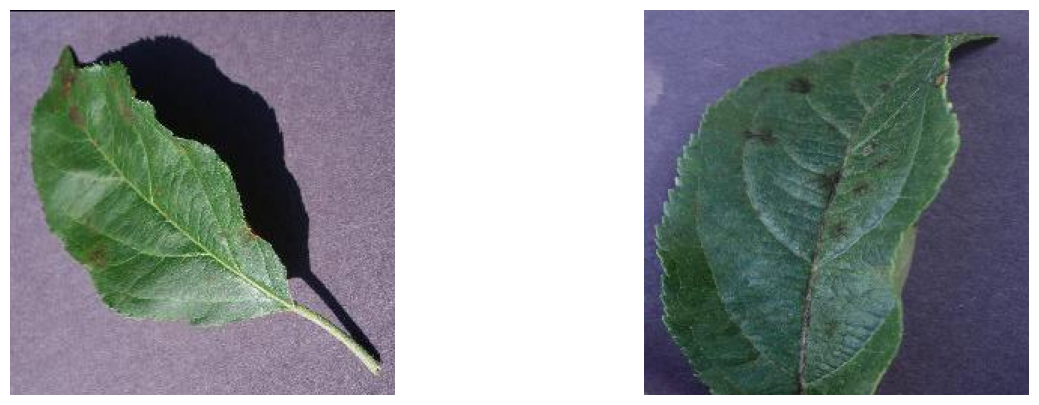

Dataset Summary:
Total images: 1900
Total classes: 38
Class 'Apple___Apple_scab': 50 images
Class 'Apple___Black_rot': 50 images
Class 'Apple___Cedar_apple_rust': 50 images
Class 'Apple___healthy': 50 images
Class 'Blueberry___healthy': 50 images
Class 'Cherry_(including_sour)___Powdery_mildew': 50 images
Class 'Cherry_(including_sour)___healthy': 50 images
Class 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 50 images
Class 'Corn_(maize)___Common_rust_': 50 images
Class 'Corn_(maize)___Northern_Leaf_Blight': 50 images
Class 'Corn_(maize)___healthy': 50 images
Class 'Grape___Black_rot': 50 images
Class 'Grape___Esca_(Black_Measles)': 50 images
Class 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)': 50 images
Class 'Grape___healthy': 50 images
Class 'Orange___Haunglongbing_(Citrus_greening)': 50 images
Class 'Peach___Bacterial_spot': 50 images
Class 'Peach___healthy': 50 images
Class 'Pepper,_bell___Bacterial_spot': 50 images
Class 'Pepper,_bell___healthy': 50 images
Class 'Potato___

In [ ]:
# small test set for debugging
# test_image_files, test_labels = load_image_file_sample(train_dir, class_names, 10)

In [ ]:

import dataset_utils
from torch.utils.data import DataLoader

dataset = dataset_utils.SuperResolutionDataset(image_files=sample_image_files)
dataloader = DataLoader(dataset, batch_size=10, shuffle=True)


In [ ]:

from generators import SimpleGenerator, ResidualGenerator, AttentionMedicalGenerator
from agricultural_sr import AgriculturalAttentionGenerator, AgriculturalDiscriminator, AgriculturalTrainer
from training_classes import AdaptiveTrainer,  MedicalTrainer, EnhancedTrainer
from discriminators import SimpleDiscriminator, SpectralNormDiscriminator


In [ ]:
#from training_loop import enhanced_training_loop

import importlib
import training_loop
import training_classes
import agricultural_sr
importlib.reload(training_loop)
importlib.reload(training_classes)
importlib.reload(agricultural_sr)
#importlib.reload(AdaptiveTrainer)
#importlib.reload(MedicalTrainer)
'''
importlib.reload(EnhancedTrainer)
importlib.reload(AgriculturalAttentionGenerator)
importlib.reload(AgriculturalDiscriminator)
importlib.reload(AgriculturalTrainer)
'''


AttributeError: `np.float_` was removed in the NumPy 2.0 release. Use `np.float64` instead.

In [ ]:
# import wandb
#wandb.login()

ImportError: cannot import name 'parse_backend_error_messages' from 'wandb.util' (/usr/local/lib/python3.12/dist-packages/wandb/util.py)

In [ ]:
# print(f"wandb version: {wandb.__version__}")

NameError: name 'wandb' is not defined

In [ ]:
# !pip uninstall wandb -y
# !rm -rf /usr/local/lib/python3*/dist-packages/wandb*

Found existing installation: wandb 0.16.6
Uninstalling wandb-0.16.6:
  Successfully uninstalled wandb-0.16.6


In [ ]:
# wandb.init(mode="disabled")

ModuleNotFoundError: No module named 'wandb.sdk.lib.gitlib'

In [ ]:
# The error indicates an internal TypeError within the wandb library, likely due to a version incompatibility.
# To fix this, we will downgrade the wandb library to a known stable version.

# Uninstall the current wandb version
# !pip uninstall wandb -y

# Install a stable version (e.g., 0.15.12)
# !pip install wandb==0.22.0

# After running this cell, please restart your Colab runtime (Runtime -> Restart runtime)
# and then re-run the subsequent cells, including wandb.login().

# Original code (commented out until wandb is fixed and runtime restarted):
generator, discriminator = training_loop.enhanced_training_loop(dataset,
                                         dataloader,
                                         agricultural_sr.AgriculturalTrainer,
                                         agricultural_sr.AgriculturalAttentionGenerator,
                                         agricultural_sr.AgriculturalDiscriminator,
                                         model_name="ag_gen_and_dis_model_500_per_class_sample_pv",
                                         num_epochs_per_block=2,
                                         total_epochs=10,
                                         checkpoint_dir="/content/drive/MyDrive/Crop Disease Detection Super Resolution/model_checkpoints",
                                        #  wandb_project_name="Agricultural-Super-Resolution",
                                         use_wandb = False
)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.6/19.6 MB 3.7 MB/s eta 0:00:00


In [ ]:
# Save models
'''
torch.save(generator.state_dict(), "/content/drive/MyDrive/Crop Disease Detection Super Resolution/ag_generator.pth")
torch.save(discriminator.state_dict(), "/content/drive/MyDrive/Crop Disease Detection Super Resolution/ag_discriminator.pth")
print("Models saved!")
'''